In [9]:
%load_ext autoreload
%autoreload 2

import sys
import os

# Definimos la ruta de la carpeta PRINCIPAL (la que contiene a twfe_tools)
ruta_proyecto = r"C:\Users\andre\Downloads\twfe_diagnostics"

if ruta_proyecto not in sys.path:
    sys.path.append(ruta_proyecto)

try:
    from twfe_tools.weights import get_jakiela_weights
    from twfe_tools.plotting import plot_weights_histogram, plot_diagnostic_heatmap
    print("✅ ¡Librería cargada exitosamente!")
except ModuleNotFoundError as e:
    print(f"❌ Error: No se encontró el módulo. Revisa que la carpeta {ruta_proyecto} tenga una carpeta llamada 'twfe_tools' con un archivo '__init__.py' adentro.")
    print(f"Tu sys.path actual es: {sys.path}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✅ ¡Librería cargada exitosamente!


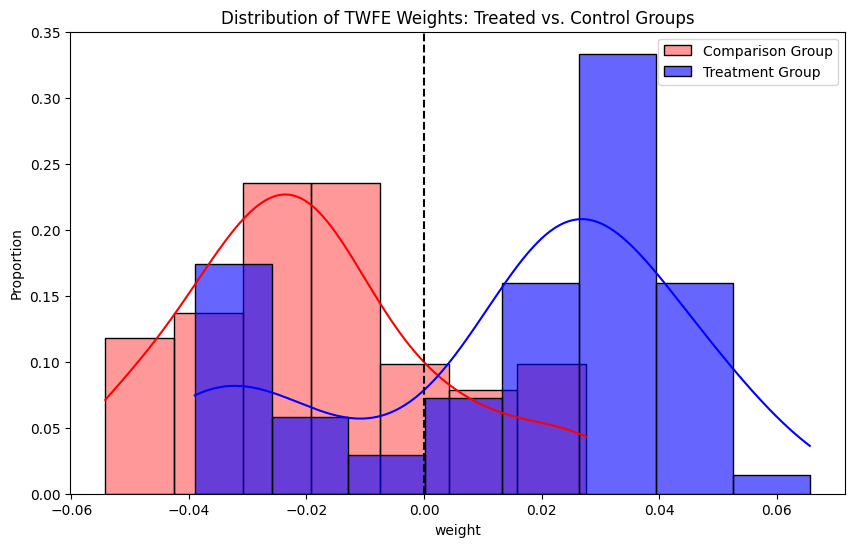

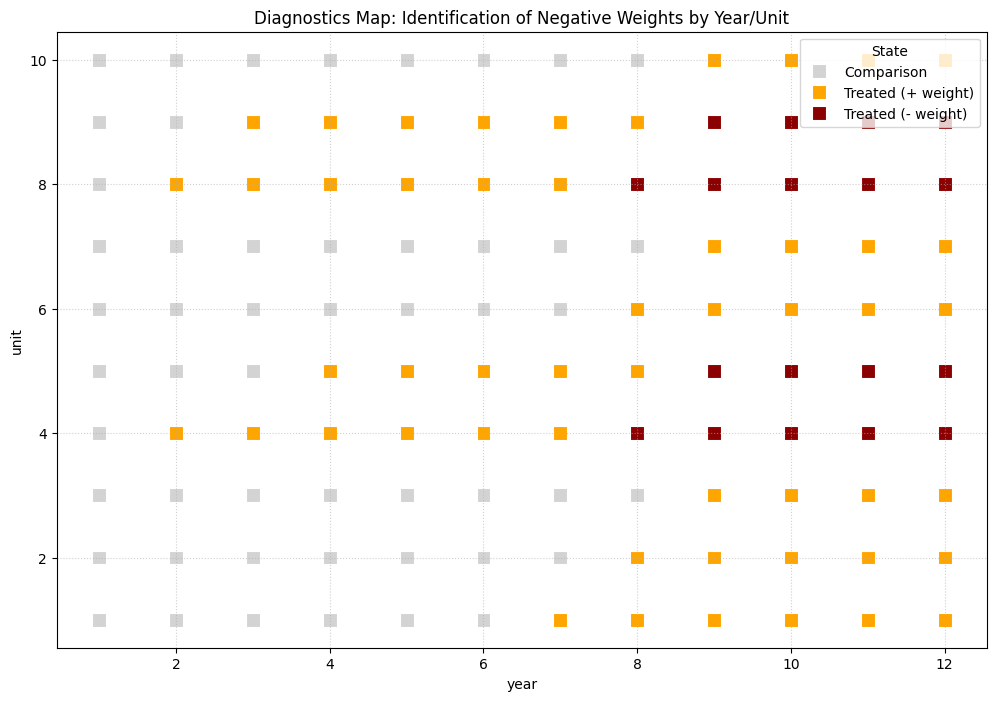

In [10]:
import sys
import os
import pandas as pd
import numpy as np

# Add the main folder to the system path so Python can find 'twfe_tools'
sys.path.append(os.path.abspath(os.path.join('..')))

# Import functions from your library
from twfe_tools.weights import get_jakiela_weights
from twfe_tools.plotting import plot_weights_histogram, plot_diagnostic_heatmap

# 1. Data Simulation (Based on EXAMPLE-diff-in-diff-slope-test-2021-03a.do)
np.random.seed(1)
n_units = 10
periods = 12
data = []

for u in range(1, n_units + 1):
    # Each unit has a different treatment start year (staggered adoption)
    fpe_year = np.random.randint(2, 10) 
    for t in range(1, periods + 1):
        treatedpost = 1 if t >= fpe_year else 0
        intensity = (t - fpe_year + 1) if treatedpost == 1 else 0
        
        # NON-LINEAR effect: grows over time, which breaks standard TWFE
        # Ref: Jakiela (2021) Example Do-file
        y_latent = 0.02 * (intensity**3) if treatedpost == 1 else 0
        y = y_latent + np.random.normal(0, 0.1)
        
        data.append({'unit': u, 'year': t, 'treatment': treatedpost, 'y': y})

df = pd.DataFrame(data)

# 2. Calculate Weights using your library
df['weight'] = get_jakiela_weights(df, 'treatment', 'unit', 'year')

# 3. Visualization
plot_weights_histogram(df)
plot_diagnostic_heatmap(df, 'unit', 'year')

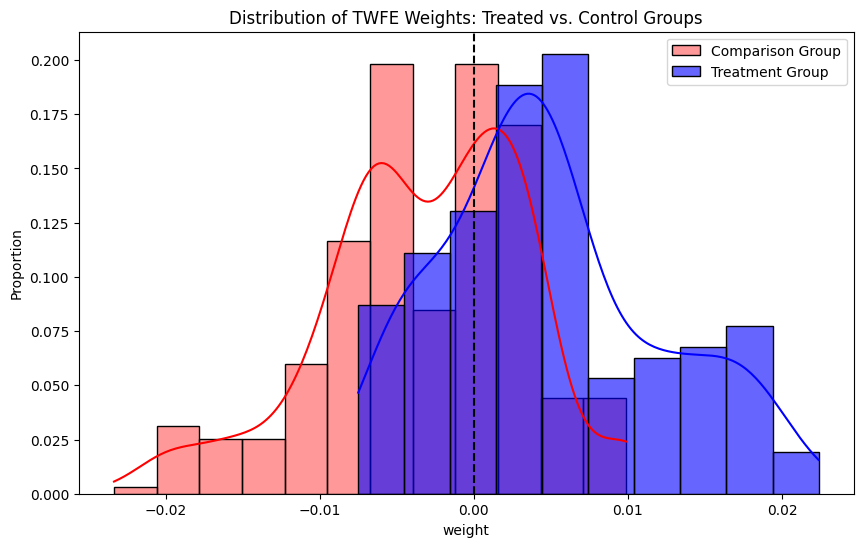

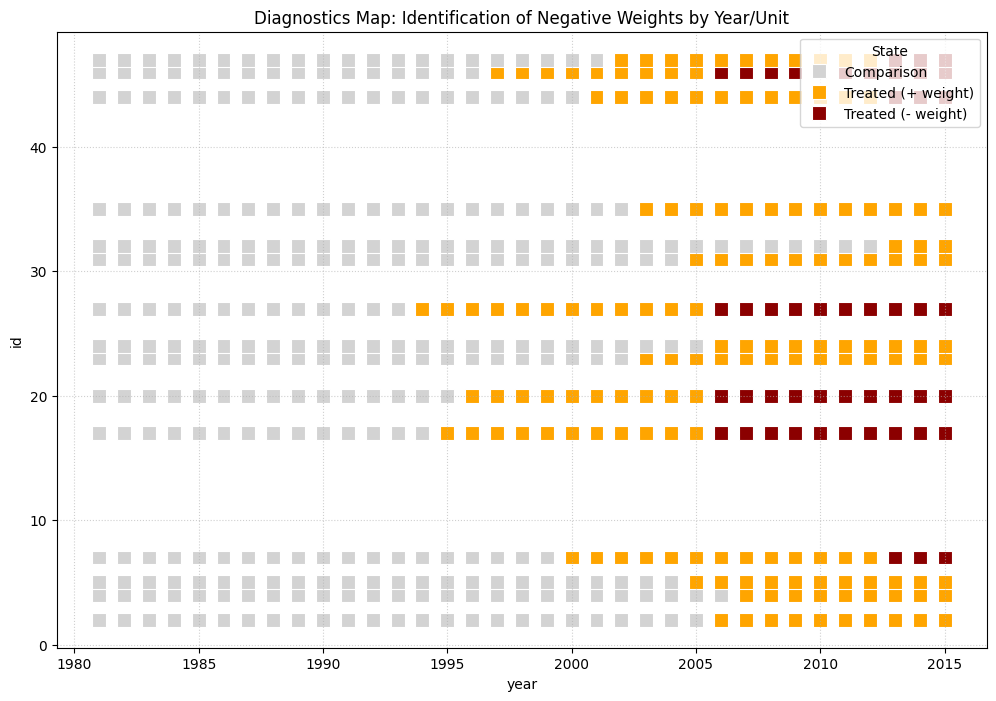

In [11]:
import sys
import os
import pandas as pd
import numpy as np

# 1. Configure Path (Ensure it points to the main project folder)
project_path = r'C:\Users\andre\Downloads\twfe_diagnostics'
if project_path not in sys.path:
    sys.path.append(project_path)

from twfe_tools.weights import get_jakiela_weights
from twfe_tools.plotting import plot_weights_histogram, plot_diagnostic_heatmap

# 2. Load data correctly using read_stata
data_path = os.path.join(project_path, "data", "WDI-FPE-data.dta")
df = pd.read_stata(data_path)

# 3. Calculate Weights
# NOTE: In this dataset, columns are 'treatment', 'id' (instead of unit), and 'year'
df['weight'] = get_jakiela_weights(df, 
                                  treatment='treatment', 
                                  unit='id', 
                                  time='year')

# 4. Visualize
# This will generate plots based on the actual data from the paper
plot_weights_histogram(df)
plot_diagnostic_heatmap(df, unit_col='id', time_col='year')

In [12]:
import sys
import os

# 1. Define la ruta a la carpeta PRINCIPAL (donde está twfe_tools)
# Asegúrate de que esta sea la ruta correcta en tu PC
ruta = r"C:\Users\andre\Downloads\twfe_diagnostics"

if ruta not in sys.path:
    sys.path.append(ruta)

# 2. Ahora intenta importar de nuevo
try:
    from twfe_tools import (
        get_jakiela_weights, 
        plot_weights_histogram, 
        run_slope_test, 
        get_weight_summary,
        plot_event_study
    )
    print("✅ Library loaded successfully!")
except ImportError as e:
    print(f"❌ Error: {e}")

✅ Library loaded successfully!


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✅ Data loaded successfully!
--- TWFE Weight Diagnostic ---
Negative weights found: 251 (47.81%)
Sum of negative weights: -1.5748
Sum of positive weights: 1.5748

--- Jakiela Slope Test Results ---
                            OLS Regression Results                            
Dep. Variable:                y_resid   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                     31.42
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           1.46e-13
Time:                        16:54:40   Log-Likelihood:                -1984.5
No. Observations:                 490   AIC:                             3975.
Df Residuals:                     487   BIC:                             3988.
Df Model:                           2                                         
Cova

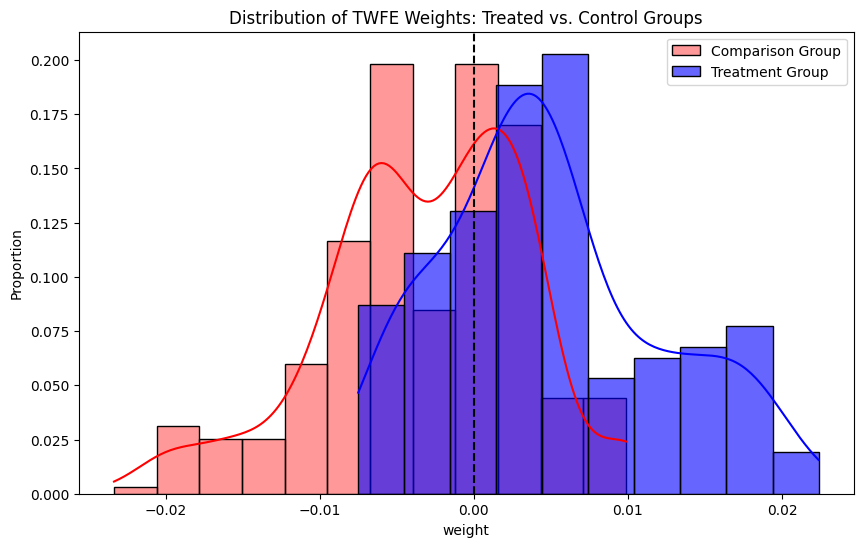

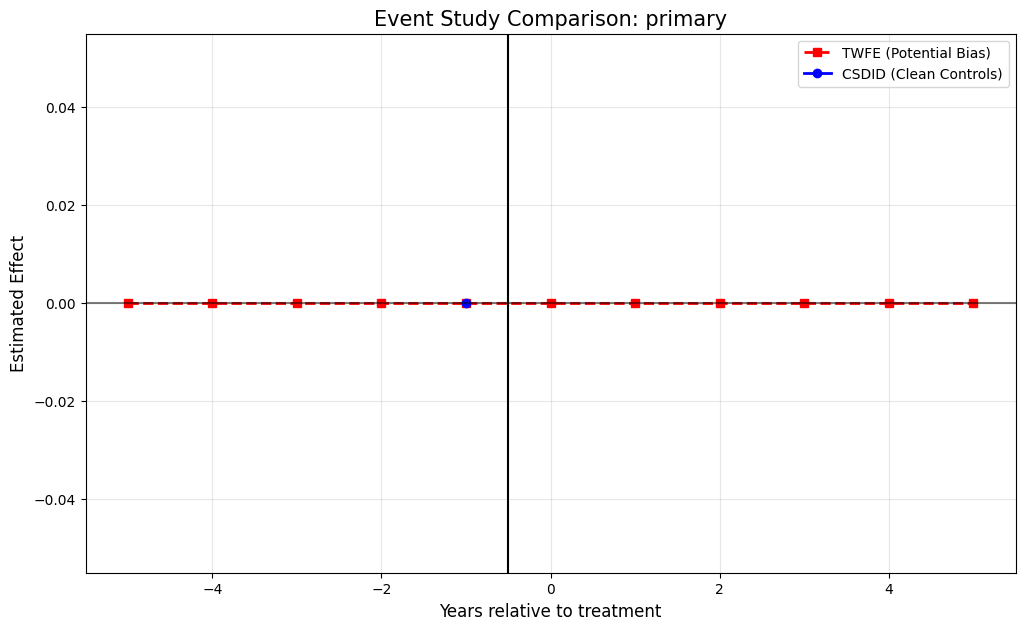

In [13]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import os
from twfe_tools import (
    get_jakiela_weights, 
    plot_weights_histogram, 
    run_slope_test, 
    get_weight_summary,
    plot_event_study
)

# 1. Load Data using Absolute Path
path_data = r"C:\Users\andre\Downloads\twfe_diagnostics\data\WDI-FPE-data.dta"

if os.path.exists(path_data):
    df = pd.read_stata(path_data)
    print("✅ Data loaded successfully!")
else:
    print(f"❌ Error: File not found at {path_data}")

# 2. Calculate Weights
df['weight'] = get_jakiela_weights(df, 'treatment', 'id', 'year')

# 3. Numerical Summary
stats = get_weight_summary(df)

# 4. Statistical Test (Jakiela Slope Test)
print("\n--- Jakiela Slope Test Results ---")
# CAMBIO: Usamos 'primary' porque es el nombre real en tu dataset
print(run_slope_test(df, y_col='primary', d_col='treatment', unit_col='id', time_col='year'))

# 5. Visual Diagnostics
plot_weights_histogram(df)

# 6. Event Study Logic
# CAMBIO: También usamos 'primary' aquí para el gráfico
df['treat_year'] = df.groupby('id')['year'].transform(lambda x: x[df['treatment'] == 1].min())
df_plot = df[df['treat_year'].notna()].copy()

if not df_plot.empty:
    plot_event_study(df_plot, y='primary', unit='id', time='year', treatment_col='treatment')

In [7]:
from twfe_tools import run_csdid_simple, run_robust_comparison

# 1. Run Standard TWFE
res_twfe = run_robust_comparison(df, 'primary', 'treatment', 'id', 'year')

# 2. Run Simplified CSDID
att_results = run_csdid_simple(df, 'primary', 'treatment', 'id', 'year')

# 3. Final Conclusion
twfe_val = res_twfe.params.iloc[0]
csdid_val = att_results['att'].mean()
diff = abs(twfe_val - csdid_val) / abs(twfe_val) * 100

print(f"\nDIAGNOSIS:")
print(f"The difference between TWFE and CSDID is {diff:.2f}%")
if diff > 10:
    print("🚨 SIGNIFICANT BIAS: The staggered adoption and negative weights")
    print("are distorting your results. Use the CSDID estimate.")
else:
    print("✅ CONSISTENT: The bias is small in this specific case.")


      STANDARD TWFE REPORT      
TWFE Coefficient: 20.4282
Std. Error     : 8.8201
P-value        : 0.0210
------------------------------

      CSDID SIMPLE REPORT      
Aggregated ATT (Clean): 32.4543
Number of Cohorts analyzed: 12
NOTE: This ATT only uses 'Never Treated' units as controls
to avoid the negative weight bias found in TWFE.

DIAGNOSIS:
The difference between TWFE and CSDID is 58.87%
🚨 SIGNIFICANT BIAS: The staggered adoption and negative weights
are distorting your results. Use the CSDID estimate.


C:\Users\andre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\linearmodels\panel\model.py:1258: MissingValueWarning: 
Inputs contain missing values. Dropping rows with missing observations.
  super().__init__(dependent, exog, weights=weights, check_rank=check_rank)
